# Episode 15: What Networks Learn: Representations
<a href="https://colab.research.google.com/github/Kinvecta/how-llms-work/blob/main/notebooks/Episode%2015%20-%20Representations.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

**Companion notebook** for the series *How Large Language Models Work: From Math to Transformers*.

This notebook reproduces the Math Lab numbers and the running-sentence experiment from Episode 15. Parts 1 and 2 use only `numpy` and the standard library, so each cell runs in a second or two. Part 3 is **our own probe experiment on GPT-2 small**: it downloads the weights once (548 MB), runs 2,048 templated sentences through the model, and trains small probes; expect a few minutes on a Colab CPU.

Covers: ReLU networks are piecewise affine with convex regions (checked on random networks), the tent fold as a hand-set network (exact arithmetic), the piece counts 2ᵏ against 2k + 1, the pin through the folded strip, the series' toy network cut into 4 and then 5 regions, and the probe experiment (block 0 at chance, unseen nouns, a control task, transfer between two sentence shapes, ranking quality, the model's own *it* versus *they* preference, and the object noun's number).

All Math Lab weights are hand-set and illustrative. The probe results are **ours, one fixed seed, templated sentences, GPT-2 small only. They show what a probe can decode, not what the model uses.** Every value that appears in the episode is checked with an `assert`. If a cell fails, a number in the episode or in the code is wrong.

## Part 1: stacked bends (hand-set weights)
### Step 1: ReLU networks are piecewise affine, with convex regions
Fix which hidden units are on (h > 0). The network is then a chain of affine maps, so it is affine. Take random 2-input networks with three layers of ReLUs; sample points; group them by their full on/off pattern. Inside a group the output must be affine along any line between two members, and the midpoint must stay in the group (convex).

In [1]:
import itertools, math, json, time
from fractions import Fraction as F
import numpy as np

checks = 0
def ok(cond, msg=""):
    global checks
    assert cond, msg
    checks += 1

groups_seen = 0
for trial in range(20):
    rg = np.random.default_rng(1000 + trial)
    W1 = rg.normal(size=(5, 2)); b1 = rg.normal(size=5)
    W2 = rg.normal(size=(4, 5)); b2 = rg.normal(size=4)
    W3 = rg.normal(size=(1, 4)); b3 = rg.normal(size=1)

    def net(u):
        h1 = W1 @ u + b1
        p1 = np.maximum(0, h1)
        h2 = W2 @ p1 + b2
        p2 = np.maximum(0, h2)
        return (W3 @ p2 + b3)[0], tuple((h1 > 0).astype(int)) + tuple((h2 > 0).astype(int))

    pts = rg.uniform(-3, 3, size=(3000, 2))
    groups = {}
    for u in pts:
        val, pat = net(u)
        groups.setdefault(pat, []).append((u, val))
    groups_seen += len(groups)
    for pat, g in groups.items():
        for (u, v), (u2, v2) in itertools.islice(itertools.combinations(g, 2), 30):
            mid = (u + u2) / 2
            vm, pm = net(mid)
            ok(pm == pat, "region not convex")                       # the midpoint has the same pattern
            ok(abs(vm - (v + v2) / 2) < 1e-9, "not affine on region")  # and the output is the average: affine
print("random networks: every region convex and affine;", groups_seen, "regions seen;", checks, "checks")

random networks: every region convex and affine; 571 regions seen; 28136 checks


### Step 2: the tent fold as a network
tent(u) = 2·ReLU(u) − 4·ReLU(u − ½) on [0, 1]: 2u up to ½, then 2 − 2u. As a network (series notation): layer 1 has W = (1, 1)ᵀ and β = (0, −½) with ψ = ReLU; each later layer has W = [[2, −4], [2, −4]] on the previous ReLU outputs and β = (0, −½); an output layer reads 2ψ₁ − 4ψ₂ after the last layer. Exact arithmetic with `Fraction`, so there is no rounding to excuse.

In [2]:
def relu(z):
    return z if z > 0 else z * 0

def tent(x):
    return 2 * x if x <= F(1, 2) else 2 - 2 * x

def tent_k(x, k):
    for _ in range(k):
        x = tent(x)
    return x

def tent_formula(x):
    return 2 * relu(x) - 4 * relu(x - F(1, 2))

def tent_net(x, k):
    """k hidden layers of 2 ReLU units each (2k units), then the readout 2*psi1 - 4*psi2."""
    h = [F(1) * x + 0, F(1) * x - F(1, 2)]
    psi = [relu(h[0]), relu(h[1])]
    for _ in range(2, k + 1):
        h = [2 * psi[0] - 4 * psi[1] + 0, 2 * psi[0] - 4 * psi[1] - F(1, 2)]
        psi = [relu(h[0]), relu(h[1])]
    return 2 * psi[0] - 4 * psi[1]

for i in range(129):
    x = F(i, 128)
    ok(tent_formula(x) == tent(x))
ok(tent(F(0)) == 0 and tent(F(1, 2)) == 1 and tent(F(1)) == 0)
for k in range(1, 9):
    M = 2 ** (k + 3)
    for i in range(M + 1):
        x = F(i, M)
        ok(tent_net(x, k) == tent_k(x, k), (k, x))
t2 = [tent_k(F(i, 8), 2) for i in range(9)]
assert t2 == [0, F(1, 2), 1, F(1, 2), 0, F(1, 2), 1, F(1, 2), 0], t2
print("the network of 2k ReLU units equals tent^k exactly (k = 1 to 8); tent^2 at multiples of 1/8:", [str(v) for v in t2])

the network of 2k ReLU units equals tent^k exactly (k = 1 to 8); tent^2 at multiples of 1/8: ['0', '1/2', '1', '1/2', '0', '1/2', '1', '1/2', '0']


### Step 3: counting the pieces
Each piece of tentᵏ⁻¹ runs monotonically from 0 to 1 or from 1 to 0, so tent's kink at ½ splits it in two, and tentᵏ has exactly 2ᵏ pieces. One hidden layer of 2k ReLU units has one breakpoint per unit, so at most 2k + 1 pieces. The expected table is copied from the episode file.

In [3]:
EXPECTED_MATH_TABLE = ['| k | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |', '| Units 2k | 2 | 4 | 6 | 8 | 10 | 12 | 14 | 16 |', '| Tent 2ᵏ | 2 | 4 | 8 | 16 | 32 | 64 | 128 | 256 |', '| One layer 2k + 1 | 3 | 5 | 7 | 9 | 11 | 13 | 15 | 17 |']

def count_pieces(k):
    # every kink of tent^k is a multiple of 2^-k, so the grid 2^-(k+3) sees each one with a point on each side
    M = 2 ** (k + 3)
    ys = [tent_k(F(i, M), k) for i in range(M + 1)]
    sl = [ys[i + 1] - ys[i] for i in range(M)]
    return 1 + sum(1 for a, b in zip(sl, sl[1:]) if a != b)

units = [2 * k for k in range(1, 9)]
deep = [count_pieces(k) for k in range(1, 9)]
shallow = [2 * k + 1 for k in range(1, 9)]
print("k      ", list(range(1, 9)))
print("units  ", units)
print("tent   ", deep)
print("1 layer", shallow)
assert deep == [2 ** k for k in range(1, 9)] == [2, 4, 8, 16, 32, 64, 128, 256]
assert shallow == [3, 5, 7, 9, 11, 13, 15, 17] and units == [2, 4, 6, 8, 10, 12, 14, 16]
overtakes = next(k for k in range(1, 9) if deep[k - 1] > shallow[k - 1])
assert overtakes == 3 and deep[2] == 8 and shallow[2] == 7              # the tent overtakes at k = 3, 8 against 7
assert deep[0] < shallow[0] and deep[1] < shallow[1]                    # not before

# the table row by row against the episode file
def cells_of(row):
    return [c.strip() for c in row.strip().strip("|").split("|")]
exp = {cells_of(r)[0]: cells_of(r)[1:] for r in EXPECTED_MATH_TABLE[1:]}
assert [str(v) for v in units] == exp["Units 2k"]
assert [str(v) for v in deep] == exp["Tent 2ᵏ"]
assert [str(v) for v in shallow] == exp["One layer 2k + 1"]
assert cells_of(EXPECTED_MATH_TABLE[0])[1:] == [str(k) for k in range(1, 9)]

# the induction step: every piece of tent^(k-1) runs monotonically onto [0, 1]
for k in range(1, 8):
    M = 2 ** (k + 3)
    ys = [tent_k(F(i, M), k) for i in range(M + 1)]
    bps = [0] + [i for i in range(1, M) if (ys[i] - ys[i - 1]) != (ys[i + 1] - ys[i])] + [M]
    ok(len(bps) - 1 == 2 ** k)
    for a, b in zip(bps[:-1], bps[1:]):
        ok({ys[a], ys[b]} == {F(0), F(1)})
        seg = ys[a:b + 1]
        ok(all(u <= v for u, v in zip(seg, seg[1:])) or all(u >= v for u, v in zip(seg, seg[1:])))

# the one-layer ceiling: 2k units in one input are affine between at most 2k breakpoints, and generic weights reach 2k + 1
rng = np.random.default_rng(14)
for k in range(1, 9):
    m = 2 * k
    for _ in range(30):
        w, b, a = rng.normal(size=m), rng.normal(size=m), rng.normal(size=m)
        c = rng.normal()
        f1 = lambda x: float((a * np.maximum(0, w * x + b)).sum() + c)
        bp = np.sort(-b / w)
        edges = np.concatenate([[bp[0] - 5], bp, [bp[-1] + 5]])
        slopes = []
        for lo, hi in zip(edges[:-1], edges[1:]):
            xs = np.linspace(lo, hi, 5)[1:-1]
            ys_ = np.array([f1(x) for x in xs])
            s = np.diff(ys_) / np.diff(xs)
            ok(np.allclose(s, s[0], atol=1e-9), "not affine between breakpoints")
            slopes.append(s[0])
        ok(len(slopes) == m + 1)
        ok(all(abs(u - v) > 1e-9 for u, v in zip(slopes, slopes[1:])))
print("one hidden layer of 2k units: at most 2k + 1 pieces (random weights reach it); the tent gets 2^k from the same 2k units")

k       [1, 2, 3, 4, 5, 6, 7, 8]
units   [2, 4, 6, 8, 10, 12, 14, 16]
tent    [2, 4, 8, 16, 32, 64, 128, 256]
1 layer [3, 5, 7, 9, 11, 13, 15, 17]


one hidden layer of 2k units: at most 2k + 1 pieces (random weights reach it); the tent gets 2^k from the same 2k units


### The pin through the folded strip
Push a pin through the folded strip at one height c, strictly between the ends (0 < c < 1): the unfolded strip has 2ᵏ holes, one per piece, because each piece runs onto all of [0, 1]. At a height equal to an end of the range the pin passes through creases and the count changes. Exact roots with `Fraction`.

The same data also fit Telgarsky's picture in words: at the points i/2ᵏ the tent network outputs exactly 0 for even i and 1 for odd i, so a threshold at ½ fits 2ᵏ alternating labels with no error (our check of the statement in the episode, not his theorem).

In [4]:
def roots_of_level(k, c):
    M = 2 ** (k + 3)
    ys = [tent_k(F(i, M), k) for i in range(M + 1)]
    bps = [0] + [i for i in range(1, M) if (ys[i] - ys[i - 1]) != (ys[i + 1] - ys[i])] + [M]
    roots = set()
    for a, b in zip(bps[:-1], bps[1:]):
        ya, yb = ys[a], ys[b]
        if min(ya, yb) <= c <= max(ya, yb):
            x = F(a, M) + (c - ya) / (yb - ya) * F(b - a, M)     # the piece is linear: solve for the crossing
            ok(tent_k(x, k) == c)
            roots.add(x)
    return roots

for k in range(1, 9):
    r_mid = roots_of_level(k, F(1, 3))
    assert len(r_mid) == 2 ** k, (k, len(r_mid))                 # one hole per piece for a pin strictly inside
    assert len(roots_of_level(k, F(1))) == 2 ** (k - 1)          # at the top of the range the pin hits the folds
    assert len(roots_of_level(k, F(0))) == 2 ** (k - 1) + 1      # at the bottom it hits the ends and creases
print("pin at height 1/3: 2^k holes for k = 1 to 8; pin at 1 or 0: 2^(k-1) and 2^(k-1) + 1")

for k in range(1, 9):
    for i in range(2 ** k):
        v = tent_net(F(i, 2 ** k), k)
        ok(v == i % 2, (k, i, v))                                # exactly 0 for even i, 1 for odd i
        ok((v > F(1, 2)) == (i % 2 == 1))
print("tent network fits 2^k alternating labels exactly at the points i/2^k (k = 1 to 8)")

pin at height 1/3: 2^k holes for k = 1 to 8; pin at 1 or 0: 2^(k-1) and 2^(k-1) + 1
tent network fits 2^k alternating labels exactly at the points i/2^k (k = 1 to 8)


## Part 2: the series' toy network, cut into regions
The 2 × 2 network of Episodes 11 to 13 (hand-set, illustrative): W = [[1, −1], [2, 1]], β = (−1, 0), W′ = [[1, 2], [1, −1]], β′ = (2, 0). In the plane of u, layer 1's lines h₁ = 0 and h₂ = 0 cut the plane into **4 regions**. The toy has no ReLU on layer 2; for this count only, add one. Then h′₁ = ψ₁ + 2ψ₂ + 2 ≥ 2 never changes sign, and h′₂ = ψ₁ − ψ₂ changes sign only where both neurons are on (along h₁ = h₂). One extra cut: **5 regions**. A grid on [−6, 6]² checks it.

In [5]:
Wt = np.array([[1, -1], [2, 1]]); bt = np.array([-1, 0])
W2t = np.array([[1, 2], [1, -1]]); b2t = np.array([2, 0])
u0 = np.array([1, 2])
h0 = Wt @ u0 + bt
assert list(h0) == [-2, 4]
assert list(W2t @ np.maximum(0, h0) + b2t) == [10, -4]                 # Episodes 11 and 12: h' = (10, -4)

xs = np.linspace(-6, 6, 1201)                                          # a 1,201 x 1,201 grid
U1, U2 = np.meshgrid(xs, xs)
H1 = U1 - U2 - 1
H2 = 2 * U1 + U2
P1, P2 = np.maximum(0, H1), np.maximum(0, H2)
Q1 = P1 + 2 * P2 + 2                                                   # h'_1
Q2 = P1 - P2                                                           # h'_2
for u in [(0.3, -1.2), (2, 5), (-4, 3.5)]:                             # the formulas equal the matrix form
    hh = Wt @ np.array(u) + bt
    ps = np.maximum(0, hh)
    hp = W2t @ ps + b2t
    assert abs(hp[0] - (ps[0] + 2 * ps[1] + 2)) < 1e-12 and abs(hp[1] - (ps[0] - ps[1])) < 1e-12

W2row = lambda r: W2t[r, 0] * P1 + W2t[r, 1] * P2 + b2t[r]            # the second layer's pre-activations straight from W' and the bias
assert np.allclose(Q1, W2row(0), atol=1e-12) and np.allclose(Q2, W2row(1), atol=1e-12)   # h'_1 = psi_1 + 2 psi_2 + 2 and h'_2 = psi_1 - psi_2
first = set(zip((H1 > 0).ravel().astype(int), (H2 > 0).ravel().astype(int)))
pats = set(zip((H1 > 0).ravel().astype(int), (H2 > 0).ravel().astype(int), (Q1 > 0).ravel().astype(int), (Q2 > 0).ravel().astype(int)))
print("layer-1 patterns:", len(first), "| patterns with a ReLU added on layer 2:", len(pats))
assert len(first) == 4 and len(pats) == 5
assert Q1.min() >= 2 - 1e-12                                           # h'_1 >= 2 everywhere: never changes sign

on1 = (H1 > 0) & ~(H2 > 0); on2 = ~(H1 > 0) & (H2 > 0)
off = ~(H1 > 0) & ~(H2 > 0); both = (H1 > 0) & (H2 > 0)
assert on1.any() and on2.any() and off.any() and both.any()
assert (Q2[on1] > 0).all() and (Q2[on2] < 0).all() and (Q2[off] == 0).all()
assert (Q2[both] > 0).any() and (Q2[both] < 0).any()                   # the one extra cut lives where both are on
assert (Q2[both & (H1 > H2 + 1e-9)] > 0).all() and (Q2[both & (H1 < H2 - 1e-9)] < 0).all()   # and it is exactly the line h1 = h2
assert np.allclose(H1 - H2, -(U1 + 2 * U2 + 1), atol=1e-12)            # the cut h1 = h2 is the line u1 + 2 u2 = -1
assert h0[0] <= 0 and h0[1] > 0 and (W2t @ np.maximum(0, h0) + b2t)[1] == -4   # u = (1, 2): neuron 1 off, neuron 2 on; h'_2 = -4
print("toy network: 4 regions from layer 1, 5 with a ReLU added on layer 2; u = (1, 2): h = (-2, 4), h'_2 = -4")

# check-question answers: k = 5 folds
assert 2 * 5 == 10 and 2 ** 5 == 32 and 2 * 5 + 1 == 11
print("MATH LAB CHECKS PASSED:", checks, "exact checks")

layer-1 patterns: 4 | patterns with a ReLU added on layer 2: 5
toy network: 4 regions from layer 1, 5 with a ReLU added on layer 2; u = (1, 2): h = (-2, 4), h'_2 = -4
MATH LAB CHECKS PASSED: 38299 exact checks


## Part 3: our probe experiment on GPT-2 small
**Our experiment, not a published result** (GPT-2 small only, templated sentences, one seed, 14). Can a *linear* probe (logistic regression, C = 1.0 fixed in advance, standardized features) read the subject's grammatical number from the 768 numbers at " because"? That is *decodable*, not "contains the subject".

*Data.* 2,048 sentences (1,024 per template): 16 animal subjects and 16 object nouns, each singular or plural, the object's number independent of the subject's. Template A: "The {S} sat on the {O} because". Template B: "On the {O} sat the {S} because". Both are 7 tokens ending in " because" (ID 780). Our running sentence is A with (cat, mat). *Split by noun:* train on 12 subject nouns, test on 4 it never saw, over 10 random choices; numbers are means. "Block k" is the checkpoint after k transformer blocks: block 0 is the token vector plus the position vector, block 12 is after the final LayerNorm (Hugging Face `hidden_states[12]`).

In [6]:
import subprocess, sys
for pkg in ["tiktoken", "safetensors", "huggingface_hub"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
import torch, tiktoken
from transformers import GPT2Config, GPT2Model
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

path = hf_hub_download("openai-community/gpt2", "model.safetensors", local_dir="gpt2_weights")
model = GPT2Model(GPT2Config())
res = model.load_state_dict(load_file(path), strict=False)
model.eval()
assert not res.missing_keys, res.missing_keys                               # every weight was loaded
assert all(k.endswith("attn.bias") or k.endswith("masked_bias") for k in res.unexpected_keys), res.unexpected_keys   # only mask buffers are left over
enc = tiktoken.get_encoding("gpt2")
print("GPT-2 small loaded;", sum(p.numel() for p in model.parameters()), "parameters in this class (no language-model head; the output layer reuses wte)")

GPT-2 small loaded; 124439808 parameters in this class (no language-model head; the output layer reuses wte)


In [7]:
SEED = 14
SUBJ = [('cat','cats'),('dog','dogs'),('bird','birds'),('horse','horses'),('bear','bears'),('goat','goats'),('duck','ducks'),('cow','cows'),
        ('pig','pigs'),('rabbit','rabbits'),('frog','frogs'),('lion','lions'),('monkey','monkeys'),('wolf','wolves'),('mouse','mice'),('snake','snakes')]
OBJ = [('mat','mats'),('box','boxes'),('chair','chairs'),('bed','beds'),('bench','benches'),('step','steps'),('log','logs'),('wall','walls'),
       ('roof','roofs'),('hill','hills'),('rock','rocks'),('stone','stones'),('fence','fences'),('floor','floors'),('table','tables'),('shelf','shelves')]
rows = []
for tpl in ('A', 'B'):
    for si, (s1, s2) in enumerate(SUBJ):
        for sn in (0, 1):
            for oi, (o1, o2) in enumerate(OBJ):
                for on in (0, 1):
                    s, o = (s1, s2)[sn], (o1, o2)[on]
                    text = f"The {s} sat on the {o} because" if tpl == 'A' else f"On the {o} sat the {s} because"
                    rows.append(dict(tpl=tpl, si=si, sn=sn, oi=oi, on=on, text=text))
ids = [enc.encode(r['text']) for r in rows]
assert len(rows) == 2048 and sum(r['tpl'] == 'A' for r in rows) == 1024
assert all(len(t) == 7 and t[-1] == 780 for t in ids)                       # 7 tokens, the last is " because" (ID 780)
assert enc.decode([780]) == " because"
full = enc.encode("The cat sat on the mat because it was tired.")
assert full[:7] == [464, 3797, 3332, 319, 262, 2603, 780] == enc.encode("The cat sat on the mat because")   # the running sentence
assert rows[[r['text'] for r in rows].index("The cat sat on the mat because")]['tpl'] == 'A'
tpl = np.array([r['tpl'] == 'B' for r in rows]); si = np.array([r['si'] for r in rows]); oi = np.array([r['oi'] for r in rows])
sn = np.array([r['sn'] for r in rows]); on = np.array([r['on'] for r in rows]); A_, B_ = ~tpl, tpl
print(len(rows), "sentences;", len(SUBJ), "subjects x 2 numbers x", len(OBJ), "objects x 2 numbers x 2 templates; every one is 7 tokens")

2048 sentences; 16 subjects x 2 numbers x 16 objects x 2 numbers x 2 templates; every one is 7 tokens


### Run the model once; keep the vector at " because" after every block
GPT-2 is causal: the state at " because" cannot depend on what follows it. The check below runs the full sentence ("…because it was tired.") and the 7-token prefix and compares the vectors at position 6 in all 13 checkpoints. The next-word scores are a linear readout of block 12 (the output layer reuses the token table W_E, Episode 11), so the model's own preference between " it" and " they" is read off the same vectors.

In [8]:
t0 = time.time()
with torch.no_grad():
    X = torch.tensor(ids)                                                   # (2048, 7)
    out = model(X, output_hidden_states=True)
    H = torch.stack([h[:, -1, :] for h in out.hidden_states], dim=1).numpy()   # (2048, 13, 768): the state at " because" after block 0..12
    wte = model.wte.weight
    lg = out.last_hidden_state[:, -1, :] @ wte.T                            # next-word scores: linear readout of block 12 with the tied table
    it_id, they_id = enc.encode(' it')[0], enc.encode(' they')[0]
    share_they = torch.sigmoid(lg[:, they_id] - lg[:, it_id]).numpy()       # P(they) / (P(it) + P(they))
    picks_they = (lg[:, they_id] > lg[:, it_id]).numpy()
    oF = model(torch.tensor([full]), output_hidden_states=True)
    oP = model(torch.tensor([full[:7]]), output_hidden_states=True)
causal = max((oF.hidden_states[L][0, 6] - oP.hidden_states[L][0, 6]).abs().max().item() for L in range(13))
print(f"H shape {H.shape}; hidden states and readout in {time.time()-t0:.1f}s; largest difference full vs prefix: {causal:.2e}")
assert H.shape == (2048, 13, 768)
assert causal < 1e-4                                                        # 0.0 in float32 on the machine that wrote the episode; allow tiny BLAS differences
assert enc.decode([it_id]) == " it" and enc.decode([they_id]) == " they"

# block 0 is the token vector plus the position vector: identical in every sentence
b0 = (model.wte.weight[780] + model.wpe.weight[6]).detach().numpy()
assert np.allclose(H[:, 0, :], b0, atol=1e-6) and np.ptp(H[:, 0, :], axis=0).max() < 1e-6
print("block 0 = wte[780] + wpe[6] in all 2,048 sentences (nothing to read at block 0)")

H shape (2048, 13, 768); hidden states and readout in 19.5s; largest difference full vs prefix: 0.00e+00
block 0 = wte[780] + wpe[6] in all 2,048 sentences (nothing to read at block 0)


### The probes
A probe is a logistic regression on standardized features, C = 1.0, trained on the subject's number (0 singular, 1 plural). Ten noun splits (split 0 uses seed 14; split s uses 14 + 100 s): 12 subject nouns train, 4 unseen nouns test, so a test set has 256 sentences per template, half plural. Per split and block we train four probes: A→A, B→B, A→B (train on template A, test on template B, unseen nouns) and B→A. We keep accuracy and AUC (ranking quality, threshold-free). The object noun's number gets its own probe on 4 unseen *object* nouns, and a control task follows.

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

def fit(Xtr, ytr, Xte, yte, C=1.0):
    sc = StandardScaler().fit(Xtr)
    clf = LogisticRegression(max_iter=3000, C=C).fit(sc.transform(Xtr), ytr)
    Z = sc.transform(Xte)
    return clf.score(Z, yte), roc_auc_score(yte, clf.decision_function(Z))

NS = 10
keys = ('AA', 'BB', 'AB', 'BA')
acc = {k: np.zeros((NS, 13)) for k in keys}
auc = {k: np.zeros((NS, 13)) for k in keys}
objacc = np.zeros((NS, 13))
split_names = []
t0 = time.time()
for s in range(NS):
    rng = np.random.default_rng(SEED + 100 * s) if s > 0 else np.random.default_rng(SEED)
    tn = rng.permutation(16)[:4]; split_names.append([SUBJ[i][0] for i in tn])
    te = np.isin(si, tn); tr = ~te
    rngo = np.random.default_rng(SEED + 1000 + s); to = rngo.permutation(16)[:4]
    teo = np.isin(oi, to); tro = ~teo                                       # four unseen OBJECT nouns for the object probe
    for L in range(13):
        Xl = H[:, L, :]
        acc['AA'][s, L], auc['AA'][s, L] = fit(Xl[A_ & tr], sn[A_ & tr], Xl[A_ & te], sn[A_ & te])
        acc['BB'][s, L], auc['BB'][s, L] = fit(Xl[B_ & tr], sn[B_ & tr], Xl[B_ & te], sn[B_ & te])
        acc['AB'][s, L], auc['AB'][s, L] = fit(Xl[A_ & tr], sn[A_ & tr], Xl[B_ & te], sn[B_ & te])
        acc['BA'][s, L], auc['BA'][s, L] = fit(Xl[B_ & tr], sn[B_ & tr], Xl[A_ & te], sn[A_ & te])
        objacc[s, L] = fit(Xl[A_ & tro], on[A_ & tro], Xl[A_ & teo], on[A_ & teo])[0]
assert len(set(map(tuple, split_names))) == NS and all(len(t) == 4 for t in split_names)
print(f"{NS} noun splits done in {time.time()-t0:.0f}s; held-out subject nouns, split 0: {split_names[0]}, split 1: {split_names[1]}")
mean = {k: acc[k].mean(0) for k in keys}
mauc = {k: auc[k].mean(0) for k in keys}
f3 = lambda a: " ".join(f"{x:.3f}" for x in a)
for k in keys:
    print(k, "accuracy by block 0..12:", f3(mean[k]))
print("AUC A->B:", f3(mauc['AB'])); print("AUC B->A:", f3(mauc['BA']))

10 noun splits done in 48s; held-out subject nouns, split 0: ['lion', 'monkey', 'bear', 'rabbit'], split 1: ['dog', 'cow', 'rabbit', 'monkey']
AA accuracy by block 0..12: 0.500 0.945 0.939 0.922 0.987 1.000 1.000 1.000 1.000 1.000 1.000 1.000 1.000
BB accuracy by block 0..12: 0.500 0.975 0.975 0.996 1.000 1.000 1.000 1.000 1.000 1.000 1.000 1.000 1.000
AB accuracy by block 0..12: 0.500 0.920 0.832 0.675 0.592 0.616 0.973 0.816 0.789 0.939 0.998 1.000 0.999
BA accuracy by block 0..12: 0.500 0.678 0.625 0.512 0.608 0.646 0.782 0.726 0.753 0.884 0.980 1.000 1.000
AUC A->B: 0.500 0.979 0.958 0.808 0.780 0.938 1.000 1.000 1.000 1.000 1.000 1.000 1.000
AUC B->A: 0.500 0.940 0.877 0.675 0.702 0.671 0.937 0.995 1.000 1.000 1.000 1.000 1.000


### Check the numbers against the episode
Block 0 is exactly chance. Within a template, unseen nouns are read almost at once. Across templates the curve is not smooth, and ranking quality (AUC) explains much of it. Tolerances: exact where the claim is exact; 0.01 for within-template numbers; 0.03 for the cross-template table and the dips (a different scikit-learn or BLAS moves them in the third decimal).

In [10]:
EXPECTED_X = ['| Block | 1 | 4 | 6 | 8 | 10 | 12 |', '| A→B | 0.920 | 0.592 | 0.973 | 0.789 | 0.998 | 0.999 |', '| B→A | 0.678 | 0.608 | 0.782 | 0.753 | 0.980 | 1.000 |']

# block 0: every unseen-noun probe is at exactly chance on the balanced test sets
for k in keys:
    assert (acc[k][:, 0] == 0.5).all(), (k, acc[k][:, 0])
# within a template, unseen nouns
assert abs(mean['AA'][1] - 0.945) < 0.01 and abs(mean['BB'][1] - 0.975) < 0.01
assert (mean['AA'][5:] > 0.999).all() and mean['AA'][4] < 0.999             # A->A is 1.000 from block 5, not before
# across templates: the episode's table, row by row
cols = [1, 4, 6, 8, 10, 12]
def cells_of(row):
    return [c.strip() for c in row.strip().strip("|").split("|")]
assert [int(c) for c in cells_of(EXPECTED_X[0])[1:]] == cols
for row in EXPECTED_X[1:]:
    name, *vals = cells_of(row)
    key = {"A→B": "AB", "B→A": "BA"}[name]
    for b, v in zip(cols, vals):
        assert abs(mean[key][b] - float(v)) < 0.03, (name, b, mean[key][b], v)
print("cross-template table matches the episode within 0.03:")
print("  block  ", cols); print("  A->B   ", [round(float(mean['AB'][b]), 3) for b in cols]); print("  B->A   ", [round(float(mean['BA'][b]), 3) for b in cols])
# not smooth, splits disagree early, recovery by block 10
assert not all(x <= y for x, y in zip(mean['AB'], mean['AB'][1:])) and not all(x <= y for x, y in zip(mean['BA'], mean['BA'][1:]))
assert mean['AB'][4] < 0.7 and mean['AB'][6] > 0.9 and (mean['AB'][10:] > 0.99).all() and (mean['BA'][10:] > 0.97).all()
lo, hi = acc['AB'][:, 1].min(), acc['AB'][:, 1].max()
print(f"A->B at block 1 over the 10 splits: {lo:.2f} to {hi:.2f}")
assert 0.70 <= lo <= 0.78 and hi > 0.99                                     # "ranges 0.73 to 1.00"
# AUC: 1.000 from block 6 (A->B) and block 8 (B->A); at blocks 3 and 4 the direction fails
assert (mauc['AB'][6:] > 0.9995).all(), mauc['AB'][6:]
assert (mauc['BA'][8:] > 0.9995).all() and 0.98 < mauc['BA'][7] < 0.9995
assert mean['AB'][8] < 0.95 and mean['BA'][8] < 0.95 and mean['AB'][9] < 0.95 and mean['BA'][9] < 0.95   # accuracy still low at blocks 8 and 9
worst = max(mauc['AB'][3], mauc['AB'][4], mauc['BA'][3], mauc['BA'][4])
print(f"AUC at blocks 3 and 4, best of the four: {worst:.3f}")
assert 0.79 < worst < 0.82                                                  # "at most 0.81"
# the object noun's number, tested on 4 unseen object nouns
objm = objacc.mean(0)
print("object-number probe, unseen object nouns, blocks 0..12:", f3(objm))
assert objm[0] == 0.5 and (objm[3:8] > 0.999).all() and abs(objm[12] - 0.940) < 0.015
print("PROBE CHECKS (part 1) PASSED")

cross-template table matches the episode within 0.03:
  block   [1, 4, 6, 8, 10, 12]
  A->B    [0.92, 0.592, 0.973, 0.789, 0.998, 0.999]
  B->A    [0.678, 0.608, 0.782, 0.753, 0.98, 1.0]
A->B at block 1 over the 10 splits: 0.73 to 1.00
AUC at blocks 3 and 4, best of the four: 0.808
object-number probe, unseen object nouns, blocks 0..12: 0.500 0.873 0.965 1.000 1.000 1.000 1.000 1.000 0.998 0.986 0.973 0.944 0.940
PROBE CHECKS (part 1) PASSED


### The control task, and the regularization check
Hewitt and Liang's idea: if a probe can fit a **random** label per word type just as well, its accuracy on the real label says little. Our version: one random 75/25 sentence split of template A (the same nouns appear in training and test), and a random 0/1 label per subject word form (32 forms). Selectivity is real accuracy minus control accuracy. Then a regularization check for the cross-template dip at block 4: the dip's depth depends on C.

In [11]:
rngc = np.random.default_rng(SEED + 7)
idxA = np.where(A_)[0]
perm = rngc.permutation(idxA); ntr = int(0.75 * len(perm))
trI, teI = perm[:ntr], perm[ntr:]
lab = np.random.default_rng(SEED + 1).integers(0, 2, size=(16, 2))
ctrl = lab[si, sn]                                                          # a random label for each subject word form
sel = []
for L in range(13):
    Xl = H[:, L, :]
    real = fit(Xl[trI], sn[trI], Xl[teI], sn[teI])[0]
    con = fit(Xl[trI], ctrl[trI], Xl[teI], ctrl[teI])[0]
    sel.append((L, real, con, real - con))
    print(f"block {L:2d}: real {real:.3f}  control {con:.3f}  selectivity {real - con:+.3f}")
for L, real, con, s_ in sel[1:]:
    assert real > 0.999 and con > 0.999 and abs(s_) < 1e-3                  # both 1.000, selectivity 0.000, at blocks 1 to 12
print("a shared-noun test cannot separate the real label from a random one: seen-noun accuracy proves little")

csens = {}
for C in (1e-4, 1.0, 100.0):
    vals = []
    for s in range(NS):
        rng = np.random.default_rng(SEED + 100 * s) if s > 0 else np.random.default_rng(SEED)
        tn = rng.permutation(16)[:4]; te = np.isin(si, tn); tr = ~te
        vals.append(fit(H[A_ & tr, 4, :], sn[A_ & tr], H[B_ & te, 4, :], sn[B_ & te], C)[0])
    csens[C] = float(np.mean(vals))
print("A->B at block 4 by C:", {c: round(v, 3) for c, v in csens.items()})
assert abs(csens[1e-4] - 0.811) < 0.03 and abs(csens[1.0] - 0.592) < 0.03 and abs(csens[100.0] - 0.553) < 0.03
assert csens[1e-4] - csens[1.0] > 0.1 and csens[1.0] > csens[100.0]         # the dip's depth depends on C

block  0: real 0.496  control 0.570  selectivity -0.074


block  1: real 1.000  control 1.000  selectivity +0.000


block  2: real 1.000  control 1.000  selectivity +0.000


block  3: real 1.000  control 1.000  selectivity +0.000


block  4: real 1.000  control 1.000  selectivity +0.000


...

block  9: real 1.000  control 1.000  selectivity +0.000


block 10: real 1.000  control 1.000  selectivity +0.000


block 11: real 1.000  control 1.000  selectivity +0.000


block 12: real 1.000  control 1.000  selectivity +0.000
a shared-noun test cannot separate the real label from a random one: seen-noun accuracy proves little


A->B at block 4 by C: {0.0001: 0.811, 1.0: 0.592, 100.0: 0.553}


### What the model itself prefers: " it" or " they"
The share P(they)/(P(it) + P(they)) over those two words only, by the subject's and object's number (sg singular, pl plural), averaged over 256 sentences per cell. The expected table is copied from the episode. The object's number shifts the share but never flips the choice.

In [12]:
EXPECTED_BEH = ['| Template | sg/sg | sg/pl | pl/sg | pl/pl |', '| A | 0.058 | 0.175 | 0.841 | 0.878 |', '| B | 0.051 | 0.139 | 0.837 | 0.887 |']

cellkeys = [(0, 0), (0, 1), (1, 0), (1, 1)]                                 # (subject number, object number): sg/sg, sg/pl, pl/sg, pl/pl
tab = {}
for t_name, tmask in (("A", A_), ("B", B_)):
    vals = []
    for a, b in cellkeys:
        mk = tmask & (sn == a) & (on == b)
        assert mk.sum() == 256
        vals.append(float(share_they[mk].mean()))
        assert picks_they[mk].mean() == (1.0 if a == 1 else 0.0), (t_name, a, b)   # " they" for every plural subject, " it" for every singular one
    tab[t_name] = vals
    print(t_name, [round(v, 3) for v in vals])
for row in EXPECTED_BEH[1:]:
    name, *vals = cells_of(row)
    for got, v in zip(tab[name], vals):
        assert abs(got - float(v)) < 0.01, (name, got, v)
for t_name in "AB":
    sgsg, sgpl, plsg, plpl = tab[t_name]
    assert sgpl < 0.5 < plsg and sgpl > sgsg and plpl > plsg               # the object shifts the share but never flips the choice
print("behaviour table matches the episode; GPT-2 prefers ' they' for 100% of plural-subject and 0% of singular-subject sentences")
print("ALL EPISODE 14 CHECKS PASSED")

A [0.058, 0.175, 0.841, 0.878]
B [0.051, 0.139, 0.837, 0.887]
behaviour table matches the episode; GPT-2 prefers ' they' for 100% of plural-subject and 0% of singular-subject sentences
ALL EPISODE 14 CHECKS PASSED


### Optional: see the two pictures
Not asserted. Left: the tent with three folds, with a dashed pin height at 1/3 crossing it at eight places. Right: unseen-noun accuracy by block for the two cross-template probes, with AUC dotted and the 0.5 line.

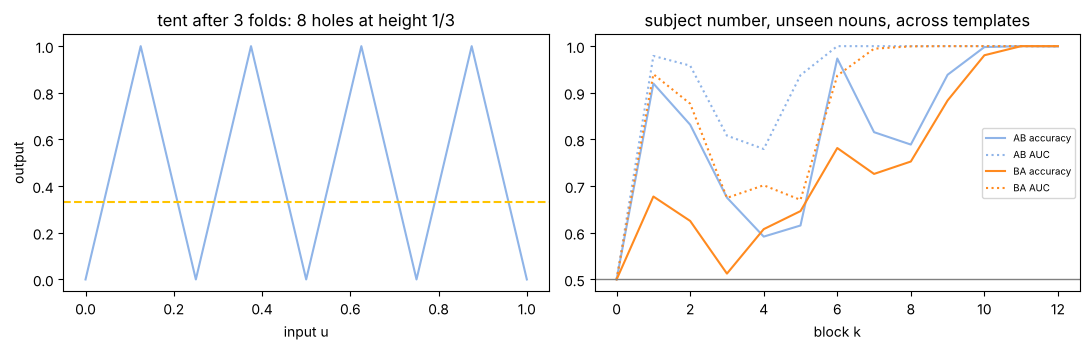

In [13]:
try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    xx = [F(i, 2 ** 9) for i in range(2 ** 9 + 1)]
    ax[0].plot([float(x) for x in xx], [float(tent_k(x, 3)) for x in xx], color="#8FB4E8")
    ax[0].axhline(1 / 3, ls="--", color="#FFC400")
    ax[0].set_title("tent after 3 folds: 8 holes at height 1/3"); ax[0].set_xlabel("input u"); ax[0].set_ylabel("output")
    for k_, c_ in (("AB", "#8FB4E8"), ("BA", "#FF8A1F")):
        ax[1].plot(range(13), mean[k_], color=c_, label=k_ + " accuracy")
        ax[1].plot(range(13), mauc[k_], color=c_, ls=":", label=k_ + " AUC")
    ax[1].axhline(0.5, color="gray", lw=1)
    ax[1].set_title("subject number, unseen nouns, across templates"); ax[1].set_xlabel("block k"); ax[1].legend(fontsize=7)
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not installed; skipping the pictures")